In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib
import warnings

warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("exams.csv")

print(df.head())

   gender race/ethnicity parental level of education         lunch  \
0    male        group A                 high school      standard   
1  female        group D            some high school  free/reduced   
2    male        group E                some college  free/reduced   
3    male        group B                 high school      standard   
4    male        group E          associate's degree      standard   

  test preparation course  math score  reading score  writing score  
0               completed          67             67             63  
1                    none          40             59             55  
2                    none          59             60             50  
3                    none          77             78             68  
4               completed          78             73             68  


In [ ]:
print(df.shape)

print(df.info())

print(df.describe())

print(df.columns)

(1000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
None
        math score  reading score  writing score
count  1000.000000    1000.000000    1000.000000
mean     66.396000      69.002000      67.738000
std      15.402871      14.737272      15.600985
min      13.000000      27.000000      23.000000
25%      56.00

In [ ]:
print(df.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [ ]:
print("Duplicate values:", df.duplicated().sum())

Duplicate values: 1


In [ ]:
df = df.drop_duplicates()

In [ ]:
print(df.dtypes)

gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object


In [ ]:
df['average_score'] = (
    df['math score'] +
    df['reading score'] +
    df['writing score']
) / 3

print(df.head())

   gender race/ethnicity parental level of education         lunch  \
0    male        group A                 high school      standard   
1  female        group D            some high school  free/reduced   
2    male        group E                some college  free/reduced   
3    male        group B                 high school      standard   
4    male        group E          associate's degree      standard   

  test preparation course  math score  reading score  writing score  \
0               completed          67             67             63   
1                    none          40             59             55   
2                    none          59             60             50   
3                    none          77             78             68   
4               completed          78             73             68   

   average_score  
0      65.666667  
1      51.333333  
2      56.333333  
3      74.333333  
4      73.000000  


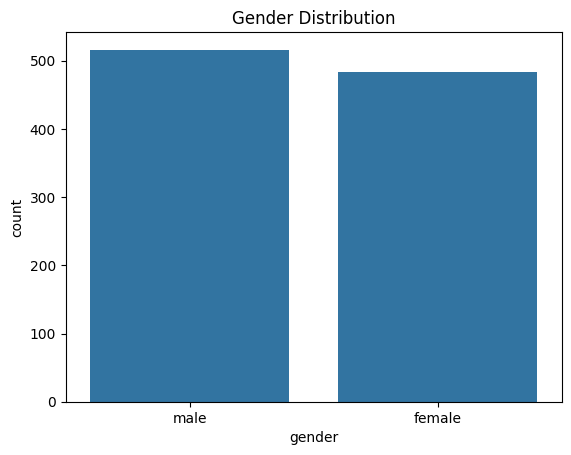

In [ ]:
sns.countplot(data=df, x='gender')

plt.title("Gender Distribution")
plt.show()

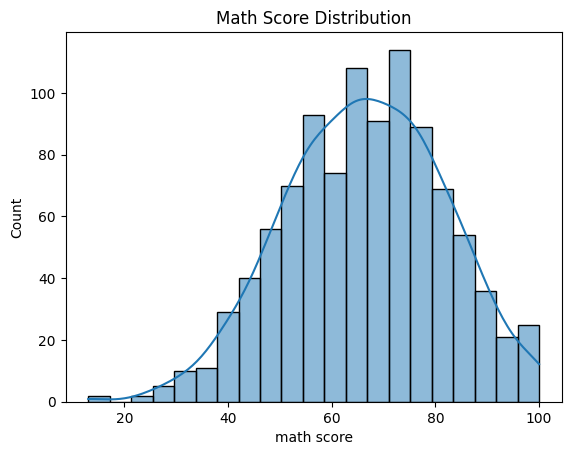

In [ ]:
sns.histplot(df['math score'], kde=True)

plt.title("Math Score Distribution")
plt.show()

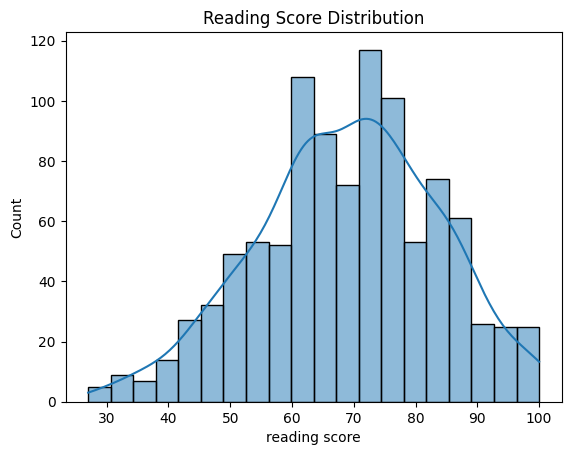

In [ ]:
sns.histplot(df['reading score'], kde=True)

plt.title("Reading Score Distribution")
plt.show()

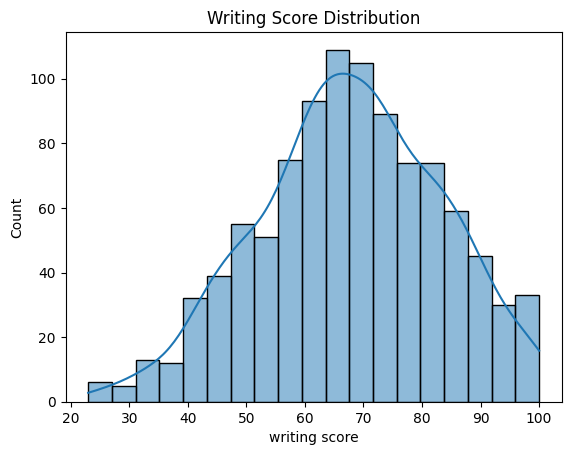

In [ ]:
sns.histplot(df['writing score'], kde=True)

plt.title("Writing Score Distribution")
plt.show()

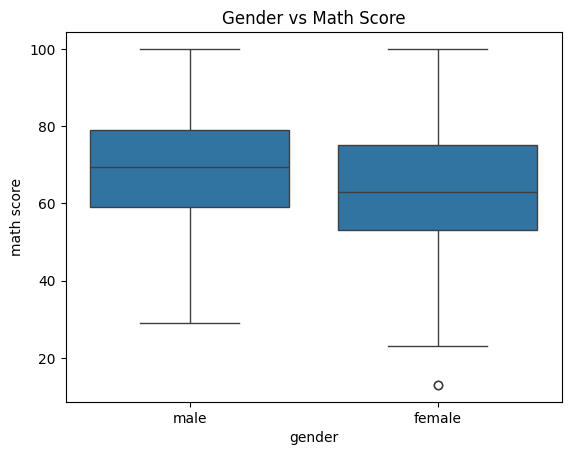

In [ ]:
sns.boxplot(data=df, x='gender', y='math score')

plt.title("Gender vs Math Score")
plt.show()

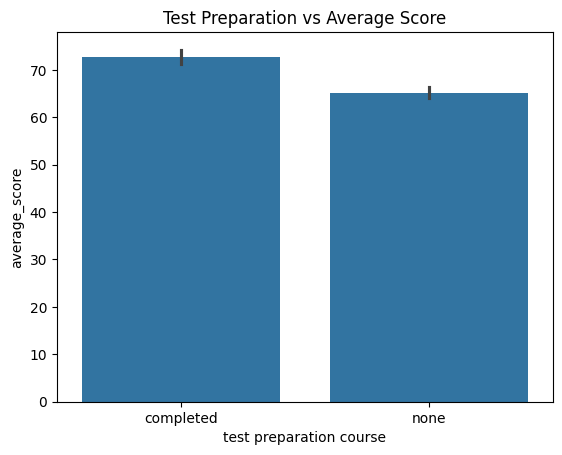

In [ ]:
sns.barplot(
    data=df,
    x='test preparation course',
    y='average_score'
)

plt.title("Test Preparation vs Average Score")
plt.show()

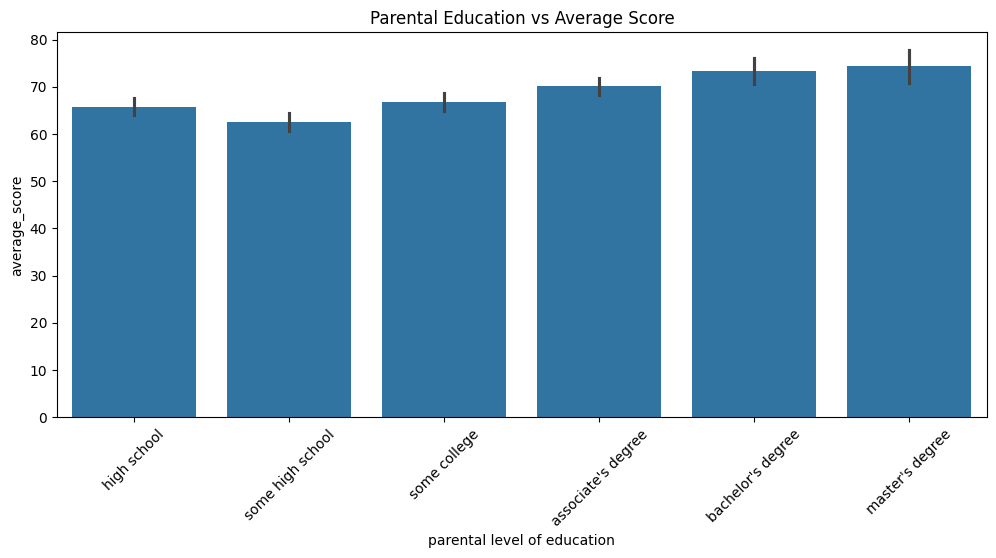

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=df,
    x='parental level of education',
    y='average_score'
)

plt.xticks(rotation=45)

plt.title("Parental Education vs Average Score")
plt.show()

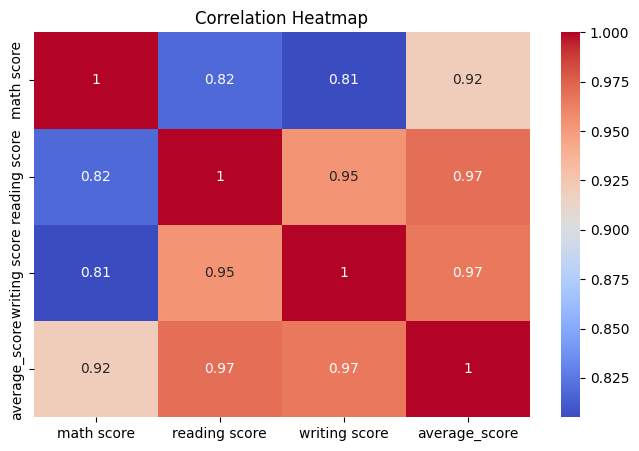

In [ ]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
X = df[
    [
        'gender',
        'race/ethnicity',
        'parental level of education',
        'lunch',
        'test preparation course'
    ]
]

y = df['average_score']

In [ ]:
categorical_features = X.select_dtypes(
    include='object'
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

Training data: (799, 5)
Testing data: (200, 5)


In [ ]:
models = {

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    )
}


results = []

trained_models = {}

for name, model in models.items():

    if name == "KNN":

        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('scaler', StandardScaler(with_mean=False)),
            ('model', model)
        ])

    else:

        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('model', model)
        ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

    trained_models[name] = pipeline


results_df = pd.DataFrame(results)

print(results_df)

               Model        MAE         MSE       RMSE  R2 Score
0  Linear Regression   9.984834  146.978306  12.123461  0.306004
1      Decision Tree  10.375533  171.894249  13.110845  0.188357
2      Random Forest  10.108576  158.578011  12.592776  0.251233
3                KNN  11.138667  182.926044  13.525016  0.136268


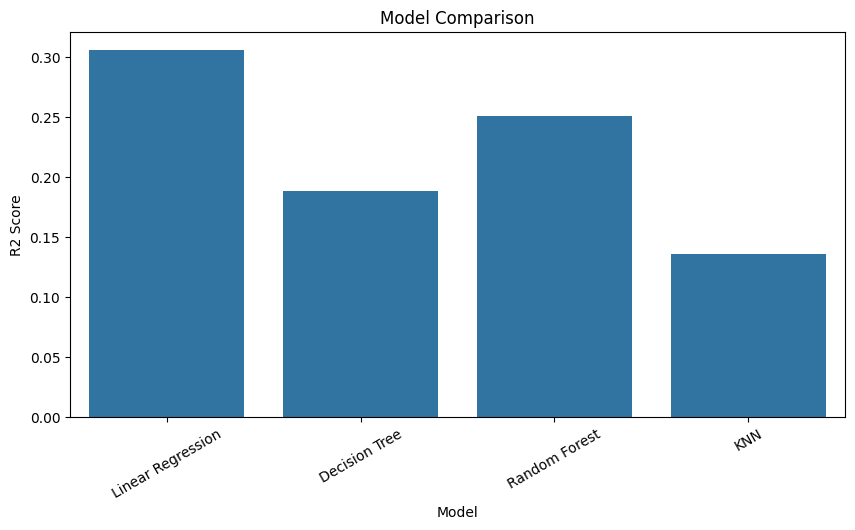

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title("Model Comparison")

plt.xticks(rotation=30)

plt.show()

In [ ]:
best_model_name = results_df.loc[
    results_df['RMSE'].idxmin(),
    'Model'
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Linear Regression


In [ ]:
cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring='r2'
)

print("Cross Validation Scores:", cv_scores)

print("Mean CV Score:", cv_scores.mean())

Cross Validation Scores: [0.29608043 0.17687252 0.30422905 0.22853584 0.24745458]
Mean CV Score: 0.25063448349699424


In [ ]:
predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Score': y_test.values,
    'Predicted Score': predictions
})

print(comparison.head(15))

    Actual Score  Predicted Score
0      50.666667        61.824838
1      67.000000        66.743823
2      64.000000        69.558370
3      78.000000        76.482155
4      52.000000        63.453796
5      70.000000        69.558370
6      66.000000        52.628700
7      77.000000        80.047776
8      70.333333        59.826298
9      68.000000        66.613142
10     42.333333        75.853999
11     84.333333        80.746792
12     75.333333        61.818302
13     71.666667        77.022843
14     45.666667        53.355203


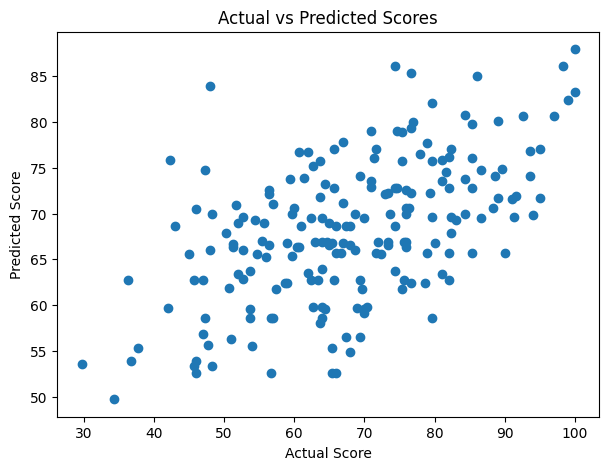

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Score")

plt.ylabel("Predicted Score")

plt.title("Actual vs Predicted Scores")

plt.show()

In [ ]:
joblib.dump(best_model, 'student_performance_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
new_student = pd.DataFrame({

    'gender': ['male'],

    'race/ethnicity': ['group B'],

    'parental level of education': [
        'bachelor\'s degree'
    ],

    'lunch': ['standard'],

    'test preparation course': ['completed']

})

prediction = best_model.predict(new_student)

print("Predicted Average Score:", prediction[0])

Predicted Average Score: 76.22202227783218


In [ ]:
pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 5.7 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 17.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
import streamlit as st
import pandas as pd
import joblib

# Load saved machine learning model
model = joblib.load("student_performance_model.pkl")

# Page configuration
st.set_page_config(
    page_title="Student Performance Prediction",
    page_icon="🎓",
    layout="centered"
)

# Application title
st.title("🎓 Student Performance Prediction")

st.write(
    "Predict a student's average examination score "
    "using Machine Learning."
)

st.divider()

# User input section
st.header("Enter Student Details")

gender = st.selectbox(
    "Gender",
    ["male", "female"]
)

race = st.selectbox(
    "Race / Ethnicity",
    [
        "group A",
        "group B",
        "group C",
        "group D",
        "group E"
    ]
)

parent_education = st.selectbox(
    "Parental Level of Education",
    [
        "some high school",
        "high school",
        "some college",
        "associate's degree",
        "bachelor's degree",
        "master's degree"
    ]
)

lunch = st.selectbox(
    "Lunch Type",
    ["standard", "free/reduced"]
)

test_preparation = st.selectbox(
    "Test Preparation Course",
    ["completed", "none"]
)

# Prediction button
if st.button("Predict Student Performance"):

    new_student = pd.DataFrame({
        "gender": [gender],
        "race/ethnicity": [race],
        "parental level of education": [parent_education],
        "lunch": [lunch],
        "test preparation course": [test_preparation]
    })

    prediction = model.predict(new_student)

    st.success("Prediction Completed!")

    st.metric(
        label="Predicted Average Score",
        value=f"{prediction[0]:.2f} / 100"
    )

    st.info(
        "This result is an estimated score generated "
        "by the Machine Learning model."
    )

2026-11-19 03:57:01.810 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 03:57:01.814 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 03:57:02.392 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-19 03:57:02.397 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 03:57:02.401 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 03:57:02.409 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-19 03:57:02.415 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# ==========================================
# 1. PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Student Report Card Lab",
    page_icon="🎓",
    layout="wide"
)

# ==========================================
# 2. LOAD MACHINE LEARNING MODEL
# ==========================================

model = joblib.load("student_performance_model.pkl")

# ==========================================
# 3. CUSTOM CSS DESIGN
# ==========================================

st.markdown("""
<style>

.stApp {
    background: linear-gradient(135deg, #10152f, #252052, #162d4a);
    color: white;
}

.main-title {
    text-align: center;
    font-size: 43px;
    font-weight: 900;
    color: white;
}

.subtitle {
    text-align: center;
    color: #c5c9ff;
    font-size: 18px;
}

div[data-testid="stMetric"] {
    background: linear-gradient(135deg, #6146d9, #2878d0);
    padding: 25px;
    border-radius: 20px;
    text-align: center;
}

div.stButton > button {
    background: linear-gradient(90deg, #8b5cf6, #06b6d4);
    color: white;
    border-radius: 15px;
    border: none;
    height: 55px;
    width: 100%;
    font-size: 19px;
    font-weight: bold;
}

div.stButton > button:hover {
    background: linear-gradient(90deg, #06b6d4, #8b5cf6);
    color: white;
    border: 1px solid white;
}

.result-card {
    background: linear-gradient(135deg, #372b78, #174c70);
    padding: 30px;
    border-radius: 22px;
    text-align: center;
    border: 1px solid #8175ff;
    margin-top: 20px;
}

.big-score {
    font-size: 65px;
    font-weight: 900;
    color: white;
}

.small-text {
    color: #d4d9ff;
    font-size: 16px;
}

</style>
""", unsafe_allow_html=True)


# ==========================================
# 4. HEADER
# ==========================================

st.markdown(
    '<div class="main-title">🎓 STUDENT REPORT CARD LAB</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">🤖 AI is ready! Let’s predict your academic future!</div>',
    unsafe_allow_html=True
)

st.write("")

st.markdown("""
<div style="text-align:center; font-size:17px;">
🔥 Your marks, your future, and a little bit of AI magic!
</div>
""", unsafe_allow_html=True)

st.divider()


# ==========================================
# 5. SIDEBAR
# ==========================================

st.sidebar.title("🎮 About This App")

st.sidebar.write("""
Welcome to Student Report Card Lab!

This application uses Machine Learning
to estimate a student's average examination score.

✨ Features:

- AI Score Prediction
- Student Performance Analysis
- Fun Result Messages
- Interactive Interface
""")

st.sidebar.info(
    "Built with Python + Streamlit + Machine Learning 🤖"
)


# ==========================================
# 6. STUDENT INPUT SECTION
# ==========================================

st.header("📝 Enter Student Details")

st.caption(
    "Fill in the details below and let AI do its magic!"
)

col1, col2 = st.columns(2)

with col1:

    gender = st.selectbox(
        "👤 Gender",
        ["male", "female"]
    )

    race = st.selectbox(
        "🌍 Race / Ethnicity",
        [
            "group A",
            "group B",
            "group C",
            "group D",
            "group E"
        ]
    )

    parent_education = st.selectbox(
        "👨‍👩‍👧 Parental Education",
        [
            "some high school",
            "high school",
            "some college",
            "associate's degree",
            "bachelor's degree",
            "master's degree"
        ]
    )

with col2:

    lunch = st.selectbox(
        "🍱 Lunch Type",
        ["standard", "free/reduced"]
    )

    test_preparation = st.selectbox(
        "📚 Test Preparation",
        ["completed", "none"]
    )

st.write("")
st.divider()


# ==========================================
# 7. PREDICTION BUTTON
# ==========================================

st.markdown(
    "<h3 style='text-align:center;'>🚀 Ready for the Big Reveal?</h3>",
    unsafe_allow_html=True
)

if st.button("✨ PREDICT MY SCORE ✨"):

    # BALLOONS EVERY TIME!
    st.balloons()

    # ======================================
    # CREATE STUDENT DATAFRAME
    # ======================================

    new_student = pd.DataFrame({
        "gender": [gender],
        "race/ethnicity": [race],
        "parental level of education": [parent_education],
        "lunch": [lunch],
        "test preparation course": [test_preparation]
    })

    # ======================================
    # MACHINE LEARNING PREDICTION
    # ======================================

    prediction = model.predict(new_student)

    score = float(prediction[0])

    display_score = max(0, min(100, score))

    # ======================================
    # PERFORMANCE ANALYSIS
    # ======================================

    if score >= 90:

        level = "🏆 LEGENDARY GENIUS!"

        message = "Are you secretly Einstein's student? 😂"

        motivation = "Keep shining! The world needs your brilliance! 🌟"

        st.snow()

    elif score >= 80:

        level = "🥇 ACADEMIC SUPERSTAR!"

        message = "Your books are clearly your best friends! 📚"

        motivation = "Amazing work! Keep reaching for the stars!"

        st.snow()

    elif score >= 70:

        level = "🔥 EXCELLENT PERFORMANCE!"

        message = "Someone is taking studies seriously! 😎"

        motivation = "You're doing great. Keep going!"

    elif score >= 60:

        level = "⭐ GOOD PERFORMANCE!"

        message = "Not bad! Your hard work is showing!"

        motivation = "A little more effort can take you higher!"

    elif score >= 50:

        level = "☕ NEEDS SOME EXTRA COFFEE!"

        message = "Maybe reduce Netflix and increase textbooks! 😂"

        motivation = "Don't give up. Every topper starts somewhere!"

    else:

        level = "💪 COMEBACK LOADING..."

        message = "Even Wi-Fi disconnects sometimes. Reconnect and try! 😂"

        motivation = "Your current score doesn't define your future!"

    # ======================================
    # 8. DISPLAY PREDICTION RESULT
    # ======================================

    st.divider()

    st.markdown(
        f"""
        <div class="result-card">
            <h2>🎉 YOUR AI RESULT IS READY!</h2>
            <div class="big-score">{display_score:.2f} / 100</div>
            <h2>{level}</h2>
            <p class="small-text">{message}</p>
        </div>
        """,
        unsafe_allow_html=True
    )

    # ======================================
    # 9. PERFORMANCE METER
    # ======================================

    st.subheader("📊 Performance Meter")

    st.progress(display_score / 100)

    st.write(
        f"Predicted Score: **{display_score:.2f}%**"
    )

    # ======================================
    # 10. MOTIVATIONAL MESSAGE
    # ======================================

    st.success("💡 " + motivation)

    # ======================================
    # 11. STUDENT PROFILE SUMMARY
    # ======================================

    st.subheader("📋 Student Profile Summary")

    result_col1, result_col2 = st.columns(2)

    with result_col1:

        st.write("👤 **Gender:**", gender)

        st.write("🌍 **Group:**", race)

        st.write(
            "🎓 **Parent Education:**",
            parent_education
        )

    with result_col2:

        st.write("🍱 **Lunch:**", lunch)

        st.write(
            "📚 **Test Preparation:**",
            test_preparation
        )

    st.divider()

    st.info(
        "🤖 This prediction is an estimated result generated "
        "by a Machine Learning model. It is not an actual "
        "examination result."
    )

    st.caption(
        "Made with ❤️ using Python, Pandas, Machine Learning & Streamlit"
    )


# ==========================================
# 12. FOOTER
# ==========================================

st.markdown("""
<div style="text-align:center; color:#aeb8e8; padding:20px;">
🎓 STUDENT REPORT CARD LAB
<br>
Powered by Machine Learning 🤖
<br>
Keep learning. Keep growing. Keep winning! 🚀
</div>
""", unsafe_allow_html=True)

Overwriting app.py


In [ ]:
!pip install streamlit pyngrok -q

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("YOUR_AUTH_TOKEN")

In [ ]:


public_url = ngrok.connect(8501)

print("STUDENTS EXAM PERFORMANCE IN EXAM:")
print(public_url)

STUDENTS EXAM PERFORMANCE IN EXAM:
NgrokTunnel: "https://wafer-monitor-rudder.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!streamlit run app.py &>/content/streamlit.log &

In [ ]:
!cat /content/streamlit.log



2026-11-19 04:08:20.804 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.24.57.74:8501



In [ ]:
from pyngrok import ngrok

# Disconnect all active tunnels dynamically
tunnels = ngrok.get_tunnels()
for tunnel in tunnels:
    print(f"Closing active tunnel: {tunnel.public_url}")
    ngrok.disconnect(tunnel.public_url)

# Safely kill the background process
ngrok.kill()

# Establish a fresh connection
try:
    public_url = ngrok.connect(8501)
    print("New Tunnel Link:", public_url)
except Exception as e:
    print("Failed to connect. If the endpoint is still locked, please wait a minute for ngrok to release the endpoint on their servers, then run this cell again.\nError details:", e)

Closing active tunnel: https://wafer-monitor-rudder.ngrok-free.dev
New Tunnel Link: NgrokTunnel: "https://wafer-monitor-rudder.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:
!cat /content/logs.txt



2026-11-19 04:18:06.180 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.24.57.74:8502



In [ ]:
!sed -i '/^%%writefile app.py$/d' app.py

In [ ]:
!python -m py_compile app.py